In [48]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict
from IPython.display import Image, display
from langchain_core.runnables.graph import MermaidDrawMethod
from langchain_openai import ChatOpenAI
import os

In [49]:
from dotenv import load_dotenv

In [50]:
load_dotenv()
model = ChatOpenAI(
  model="gpt-4o-mini",
  api_key=os.environ.get("OPENAI_API_KEY")
)

In [51]:
class OutlineState(TypedDict):
  topic: str
  outline: str
  blog: str

In [52]:
graph = StateGraph(OutlineState)

In [53]:
def write_outline(state: OutlineState) -> OutlineState:
  topic = state['topic']
  prompt = f"Write an outline for a blog post about {topic}."
  outline = model.invoke(prompt).content
  state['outline'] = outline
  return state

In [54]:
def generate_blog(state: OutlineState) -> OutlineState:
  topic = state['topic']
  outline = state['outline']
  prompt = f"Write a blog post based on the following outline:\n\n{outline}"
  blog = model.invoke(prompt).content
  state['blog'] = blog
  return state

In [55]:
graph.add_node("write_outline",write_outline) 
graph.add_node("generate_blog",generate_blog) 

In [56]:
graph.add_edge(START, "write_outline")
graph.add_edge("write_outline", "generate_blog")
graph.add_edge("generate_blog", END)

workflow = graph.compile()

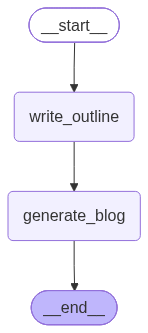

In [57]:
workflow

In [58]:
ans = workflow.invoke({
  "topic": "Python Programming"
})

print(ans['outline'])

# Blog Post Outline: Introduction to Python Programming

## I. Introduction
   - A. Brief Overview of Python
       1. What is Python?
       2. History and development
   - B. Importance of Python in today's tech landscape
       1. Popularity and usage statistics
       2. Applications in various fields (web development, data analysis, artificial intelligence, etc.)
   - C. Purpose of the blog post
       1. To provide an understanding of Python for beginners
       2. To inspire readers to learn and experiment with Python

## II. Getting Started with Python
   - A. Installing Python
       1. Downloading and installing Python
       2. Setting up an IDE (Integrated Development Environment) or text editor (e.g., PyCharm, VS Code)
   - B. Writing Your First Python Program
       1. Creating a "Hello, World!" program
       2. Understanding the syntax and output

## III. Python Basics
   - A. Data Types and Variables
       1. Introduction to basic data types (integers, floats, strings

In [61]:
print(ans["blog"])

# Introduction to Python Programming

## I. Introduction

### A. Brief Overview of Python
Python is a versatile high-level programming language designed for ease of reading and simplicity. Developed by Guido van Rossum and first released in 1991, it has grown exponentially in popularity over the years. Python’s clean syntax, coupled with its wide array of libraries, makes it an excellent choice for both novice and experienced programmers alike.

### B. Importance of Python in Today's Tech Landscape
Python currently stands as one of the most popular programming languages in the world, consistently ranking high on various coding indexes. According to the TIOBE Index, Python is often among the top 3 languages, thanks in part to its expansive use across diverse fields. From web development and data analysis to artificial intelligence and beyond, Python is a staple in many sectors, helping users automate tasks, analyze data, and build robust applications.

### C. Purpose of the Blog Post
Th